# Sentiment BERT et comparaison du modèle

## 1. Objectif

Campagne du **02/09/2026** : score DistilBERT agrégé **par jour UTC** dans `dim_news_sentiment`, puis LightGBM **avec / sans** actualités. Cible = **durée observée**, pas un retard.

Les cellules et le tableau de la partie 5 sont ce run (13 822 vols, RMSE ~73).

Le livrable de référence est le **Rendu 3 (04/09)** : 21 054 vols, LightGBM **54,02** vs médiane **44,07**. Décision (garder BERT en entrepôt, ne pas l'utiliser comme un gain) : `docs/experience_actualites_bert.md`.

Aucun appel API ici. DistilBERT a déjà tourné en CLI (`python -m src.processing.scorer_sentiment`) ; je **lis** les scores en base (pas de rechargement des poids, RAM).


In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

RACINE_PROJET = os.path.abspath(os.path.join(os.getcwd(), ".."))
if RACINE_PROJET not in sys.path:
    sys.path.insert(0, RACINE_PROJET)
os.chdir(RACINE_PROJET)

from src.database.db_connector import creer_engine
from src.models.entrainer import executer_pipeline
from src.models.jeu import charger_vols_meteo, diagnostiquer_volumetrie
from src.processing.scorer_sentiment import MODELE_SENTIMENT_DEFAUT

pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore", message="Pandas requires version")
print("Modèle HuggingFace utilisé en CLI :", MODELE_SENTIMENT_DEFAUT)

C:\Users\jeann\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Modèle HuggingFace utilisé en CLI : lxyuan/distilbert-base-multilingual-cased-sentiments-student


## 2. Météo du même jour

`collecter_hubs` interroge OpenWeather *current* **à la fin** de la salve, une fois par hub. Le 02/09 : 10 lignes nouvelles dans `dim_weather` (100 → 110). L'ETL ne rattache que si l'écart à `first_seen` / `last_seen` ≤ 3 h. Un snapshot ne couvre pas les 24 h OpenSky.

D'où, **sur ce run** : 13 822 vols, mais seulement 3 034 avec météo origine **et** durée. Recolter des vols sans étaler la météo n'agrandit presque pas X. L'essai d'archive horaire (Open-Meteo) est dans `docs/experience_meteo_openmeteo.md` — non retenu.


In [2]:
engine = creer_engine()
with engine.connect() as connexion:
    nb_meteo = connexion.execute(text("SELECT COUNT(*) FROM dim_weather")).scalar_one()
    nb_vols = connexion.execute(text("SELECT COUNT(*) FROM fact_flights")).scalar_one()
    nb_jours_actu = connexion.execute(
        text("SELECT COUNT(*) FROM dim_news_sentiment")
    ).scalar_one()
    scores_null = connexion.execute(
        text(
            "SELECT COUNT(*) FROM dim_news_sentiment WHERE score_sentiment IS NULL"
        )
    ).scalar_one()
    dernieres_meteo = pd.read_sql(
        text(
            """
            SELECT airport_id, horodatage_observation, temperature_celsius, wind_speed
            FROM dim_weather
            ORDER BY horodatage_observation DESC
            LIMIT 12
            """
        ),
        connexion,
    )

print(f"fact_flights : {nb_vols}")
print(f"dim_weather : {nb_meteo}")
print(f"dim_news_sentiment : {nb_jours_actu} jours, score NULL : {scores_null}")
dernieres_meteo

fact_flights : 13822
dim_weather : 110
dim_news_sentiment : 27 jours, score NULL : 0


,airport_id,horodatage_observation,temperature_celsius,wind_speed
0,10,2026-09-02 10:28:27+00:00,30.60,4.63
1,1,2026-09-02 10:28:27+00:00,21.94,3.09
2,7,2026-09-02 10:28:27+00:00,26.12,5.36
3,6,2026-09-02 10:28:27+00:00,32.18,3.60
4,9,2026-09-02 10:28:27+00:00,22.27,1.54
5,8,2026-09-02 10:28:27+00:00,17.14,3.09
6,3,2026-09-02 10:28:27+00:00,22.39,2.06
7,2,2026-09-02 10:28:27+00:00,18.20,5.66
8,4,2026-09-02 10:28:27+00:00,20.48,7.20
9,5,2026-09-02 10:28:27+00:00,28.46,1.03


## 3. BERT : grain jour, pas vol

NewsAPI n'a pas de clé article ↔ vol. Le score vit dans `dim_news_sentiment.score_sentiment` (moyenne des polarités d'articles du jour, polarité = P(positive) − P(negative), intervalle [−1, 1]).

- Modèle : DistilBERT **multilingue** (FR/EN du corpus), inférence **CPU**.
- Entrée : titre + description des JSON `newsapi_*.json` (pas le `content` tronqué du plan gratuit).
- Pas dans l'image Docker de l'API (`requirements-api.txt` sans `torch`).

CLI (déjà exécutée le 02/09) : `python -m src.processing.scorer_sentiment` → 185 articles, 27 jours mis à jour.

       score_sentiment
count        27.000000
mean         -0.251915
std           0.240649
min          -0.787893
25%          -0.429439
50%          -0.173291
75%          -0.087259
max           0.035419
Jours avec score : 27 / 27


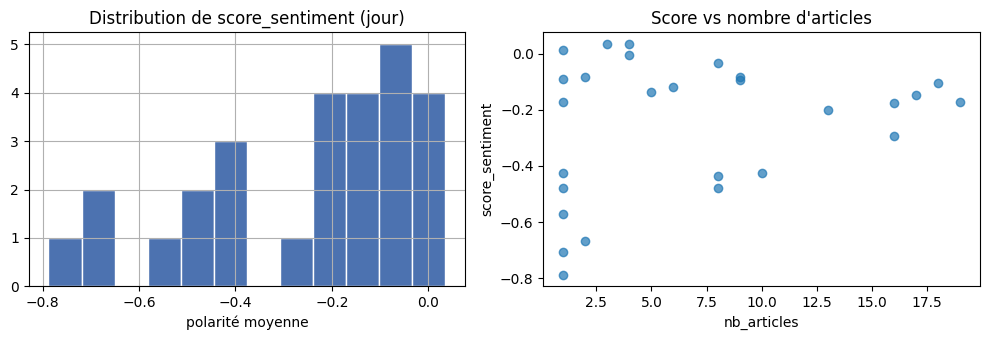

,date_id,nb_articles,score_sentiment
19,20260825,17,-0.147357
20,20260826,9,-0.081211
21,20260827,8,-0.480346
22,20260828,16,-0.293036
23,20260829,4,0.035374
24,20260830,6,-0.118710
25,20260831,8,-0.434336
26,20260901,3,0.035419


In [3]:
with engine.connect() as connexion:
    news = pd.read_sql(
        text(
            """
            SELECT date_id, nb_articles, score_sentiment
            FROM dim_news_sentiment
            ORDER BY date_id
            """
        ),
        connexion,
    )

print(news[["score_sentiment"]].describe())
print("Jours avec score :", int(news["score_sentiment"].notna().sum()), "/", len(news))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
news["score_sentiment"].hist(ax=axes[0], bins=12, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution de score_sentiment (jour)")
axes[0].set_xlabel("polarité moyenne")
axes[1].scatter(news["nb_articles"], news["score_sentiment"], alpha=0.7)
axes[1].set_title("Score vs nombre d'articles")
axes[1].set_xlabel("nb_articles")
axes[1].set_ylabel("score_sentiment")
plt.tight_layout()
plt.show()
news.tail(8)

## 4. Comment le score entre dans LightGBM ?

`score_sentiment` n'est **pas** une colonne de X (fuite / grain jour trop grossier en brut).

`ajouter_features_actu` remplit `proxy_perturbation_actu` avec ce score s'il n'est pas NULL, sinon un lexique sur `mots_cles`. `nb_articles_actu` reste une feature séparée.

Même split, mêmes baselines : `executer_pipeline(..., avec_actu=True)` vs `avec_actu=False`.

In [4]:
df = charger_vols_meteo()
diag = diagnostiquer_volumetrie(df)
print(
    "Vols / jours / météo+durée / news scorés / jours communs :",
    diag["nb_vols"],
    diag["nb_jours"],
    diag["meteo_et_duree"],
    diag["news_score_non_null"],
    diag["nb_jours_news_recouvrants"],
)

rapport_sans = executer_pipeline(sauvegarder=False, avec_actu=False)
rapport_avec = executer_pipeline(sauvegarder=False, avec_actu=True)

lignes = []
for nom, rap in (("sans actu", rapport_sans), ("avec actu + BERT", rapport_avec)):
    lignes.append(
        {
            "variante": nom,
            "n_train": rap["n_train"],
            "n_test": rap["n_test"],
            "rmse_lgbm": round(rap["metriques_modele"]["rmse"], 2),
            "rmse_mediane": round(rap["metriques_baseline"]["rmse"], 2),
            "rmse_horaire": round(rap["metriques_baseline_horaire"]["rmse"], 2),
            "bat_mediane": rap["bat_la_baseline"],
            "bat_horaire": rap["bat_la_baseline_horaire"],
        }
    )
pd.DataFrame(lignes)

2026-09-02 12:37:39,468 - src.models.jeu - INFO - Jeu brut chargé : 13822 ligne(s), 28 colonne(s).


Vols / jours / météo+durée / news scorés / jours communs : 13822 8 3034 13098 7


2026-09-02 12:37:40,129 - src.models.jeu - INFO - Jeu brut chargé : 13822 ligne(s), 28 colonne(s).
2026-09-02 12:37:40,183 - src.models.entrainer - WARNING - Diagnostic volumétrie : cible C. Entraînement sur B (durée observée ; retard_minutes est un écart à la médiane de route, pas un horaire programmé).
2026-09-02 12:37:40,187 - src.models.jeu - INFO - Jeu modèle : 3034 ligne(s) avec météo origine et durée observée.
2026-09-02 12:37:40,208 - src.models.jeu - INFO - Durées aberrantes : 154 ligne(s) exclue(s) (plafond 480 min).
2026-09-02 12:37:40,221 - src.models.jeu - INFO - Split temporel : train=2016 (jusqu'à 2026-09-01T12:55:12+00:00), test=864 (depuis 2026-09-01T12:56:05+00:00).
2026-09-02 12:37:40,492 - src.models.entrainer - INFO - Cible duree_minutes (B). Train=2016, test=864, durées > 480 min exclues=154. Actualités : non. LightGBM RMSE=73.63 MAE=56.92. Baseline médiane globale RMSE=73.19 MAE=43.50. Baseline médiane par heure UTC RMSE=67.94 MAE=36.90. Bat la globale : False. B

,variante,n_train,n_test,rmse_lgbm,rmse_mediane,rmse_horaire,bat_mediane,bat_horaire
0,sans actu,2016,864,73.63,73.19,67.94,False,False
1,avec actu + BERT,2016,864,73.44,73.19,67.94,False,False


In [5]:
imp = rapport_avec.get("importance_features") or {}
ordre = sorted(imp.items(), key=lambda item: -item[1])
pd.DataFrame(ordre, columns=["feature", "importance_splits"]).head(12)

,feature,importance_splits
0,heure_utc,1072
1,temperature_origine,200
2,vent_origine,140
3,hub_origine,129
4,humidite_origine,117
5,temperature_dest,110
6,jour_semaine,92
7,vent_dest,48
8,mois,21
9,nb_articles_actu,21


## 5. Conclusion (CLI 02/09/2026 12:31)

| Variante | LightGBM RMSE | Médiane globale | Médiane horaire |
| --- | --- | --- | --- |
| Sans actu | 73,63 | 73,19 | 67,94 |
| Avec actu + BERT | 73,44 | 73,19 | 67,94 |

Train 2016 / test 864. Actu + BERT : −0,19 RMSE. LightGBM **perd** encore contre les deux médianes. Grain = **jour** ; l'heure UTC domine.

**Décision.** Je garde le score en entrepôt. Je ne l'utilise pas comme un gain. Joblib / API inchangés.

Ces chiffres sont le **02/09**. Détail des pistes testées le jour même : `docs/experience_actualites_bert.md`.